# AegisLife Insurance – Risk Analysis Capstone

## Objective
To analyze customer risk, policy characteristics, claims, fraud indicators and customer feedback to identify important risk patterns and provide actionable business recommendations.

## Tools
- Excel – Data validation and cleaning
- MySQL – Database management and SQL analysis
- Python – EDA and statistical analysis
- Power BI – Interactive dashboard

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind, f_oneway, chi2_contingency

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [2]:
file_path = r"C:\Users\lenovo\Desktop\AegisLife_Data_Validation_backup - Copy2.xlsx"

print(file_path)

C:\Users\lenovo\Desktop\AegisLife_Data_Validation_backup - Copy2.xlsx


In [3]:
import os

print(os.path.exists(file_path))

True


In [4]:
excel = pd.ExcelFile(file_path)

excel.sheet_names

['Customer_Master',
 'Policy_Details',
 'Claim_History',
 'Agent_Info',
 'Customer_Feedback',
 'Data_Quality_Log',
 'Validation_Summary']

In [5]:
customer = pd.read_excel(
    file_path,
    sheet_name="Customer_Master",
    usecols="A:K"
)

print("Customer shape:", customer.shape)

display(customer.head())

Customer shape: (1648, 11)


,customer_id,full_name,age,gender,marital_status,occupation,region,smoking_status,pre_existing_illness,risk_score,date_joined
0,CUST10000,Yahvi Chander,18,Male,Single,Student,West,No,Yes,0.61,2020-02-02
1,CUST10001,Gautami Batta,39,Female,Divorced,Salaried,East,Yes,Yes,0.56,2020-04-17
2,CUST10002,Zehaan Randhawa,34,Male,Single,Student,North,Yes,No,0.48,2018-06-27
3,CUST10003,Aarnav Bhandari,50,Male,Married,Self-employed,South,Yes,No,0.47,2021-12-02
4,CUST10005,Tripti Parekh,20,Female,Single,Student,North,Yes,No,0.55,2022-10-25


In [7]:
policy = pd.read_excel(
    file_path,
    sheet_name="Policy_Details",
    usecols="A:H"
)

claims = pd.read_excel(
    file_path,
    sheet_name="Claim_History",
    usecols="A:H"
)

agents = pd.read_excel(
    file_path,
    sheet_name="Agent_Info",
    usecols="A:G"
)

feedback = pd.read_excel(
    file_path,
    sheet_name="Customer_Feedback",
    usecols="A:G"
)

print("Customer:", customer.shape)
print("Policy:", policy.shape)
print("Claims:", claims.shape)
print("Agents:", agents.shape)
print("Feedback:", feedback.shape)

Customer: (1648, 11)
Policy: (2828, 8)
Claims: (1406, 8)
Agents: (300, 7)
Feedback: (1000, 7)


In [8]:
print("Policy columns:")
print(policy.columns.tolist())

print("\nClaims columns:")
print(claims.columns.tolist())

print("\nAgent columns:")
print(agents.columns.tolist())

print("\nFeedback columns:")
print(feedback.columns.tolist())

Policy columns:
['policy_id', 'customer_id', 'product_type', 'coverage_amount', 'annual_premium', 'policy_start_date', 'policy_end_date', 'agent_id']

Claims columns:
['claim_id', 'policy_id', 'claim_date', 'claim_amount', 'claim_status', 'claim_type', 'fraud_flag', 'days_to_process']

Agent columns:
['agent_id', 'region', 'join_date', 'total_policies_sold', 'lapsed_policies', 'avg_premium_sold', 'fraud_association']

Feedback columns:
['feedback_id', 'customer_id', 'date_submitted', 'feedback_text', 'satisfaction_score', 'contacted_agent', 'referred_claim']


In [9]:
datasets = {
    "Customer": customer,
    "Policy": policy,
    "Claims": claims,
    "Agents": agents,
    "Feedback": feedback
}

for name, df in datasets.items():
    print("\n" + "="*50)
    print(name)
    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Duplicate rows:", df.duplicated().sum())
    print("Missing values:", df.isnull().sum().sum())


Customer
Rows: 1648
Columns: 11
Duplicate rows: 0
Missing values: 0

Policy
Rows: 2828
Columns: 8
Duplicate rows: 0
Missing values: 0

Claims
Rows: 1406
Columns: 8
Duplicate rows: 0
Missing values: 0

Agents
Rows: 300
Columns: 7
Duplicate rows: 0
Missing values: 0

Feedback
Rows: 1000
Columns: 7
Duplicate rows: 0
Missing values: 0


In [10]:
customer["date_joined"] = pd.to_datetime(customer["date_joined"], errors="coerce")

policy["policy_start_date"] = pd.to_datetime(policy["policy_start_date"], errors="coerce")
policy["policy_end_date"] = pd.to_datetime(policy["policy_end_date"], errors="coerce")

claims["claim_date"] = pd.to_datetime(claims["claim_date"], errors="coerce")

agents["join_date"] = pd.to_datetime(agents["join_date"], errors="coerce")

feedback["date_submitted"] = pd.to_datetime(feedback["date_submitted"], errors="coerce")

print("Dates converted successfully.")

Dates converted successfully.


## BASIC RISK ANALYSIS

### Risk score summary

In [16]:
customer["risk_score"].describe()

count    1648.000000
mean        0.495752
std         0.195867
min         0.000000
25%         0.360000
50%         0.500000
75%         0.620000
max         1.000000
Name: risk_score, dtype: float64

### Risk category

In [13]:
customer["risk_category"] = pd.cut(
    customer["risk_score"],
    bins=[-np.inf, 0.30, 0.70, np.inf],
    labels=["Low Risk", "Medium Risk", "High Risk"])

customer["risk_category"].value_counts()

risk_category
Medium Risk    1149
Low Risk        265
High Risk       234
Name: count, dtype: int64

### Risk chart

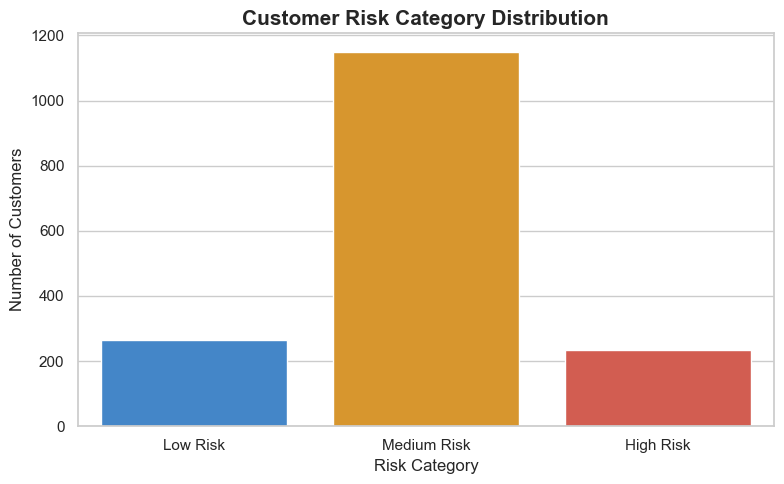

In [19]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=customer,
    x="risk_category",
    hue="risk_category",
    palette=["#2E86DE", "#F39C12", "#E74C3C"],
    legend=False
)

plt.title(
    "Customer Risk Category Distribution",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

## Major risk drivers:-

### Smoking Status :

In [23]:
customer.groupby("smoking_status")["risk_score"].agg( ["count", "mean"]).sort_values("mean", ascending=False)

,count,mean
smoking_status,,
No,855,0.505649
Yes,793,0.485082


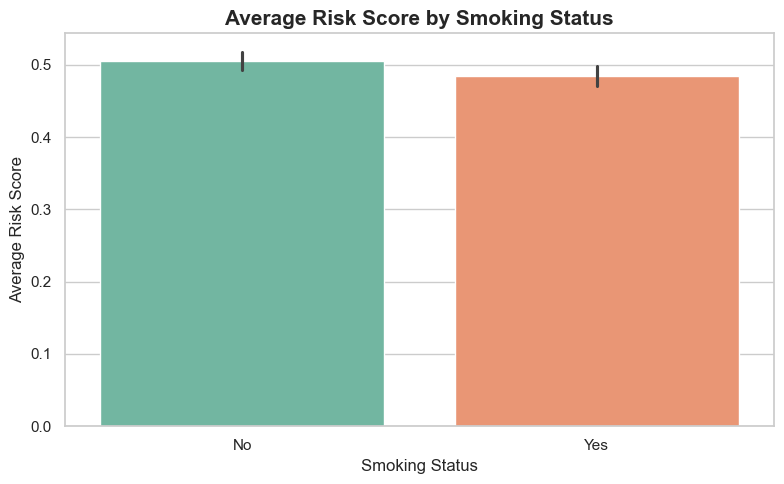

In [21]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=customer,
    x="smoking_status",
    y="risk_score",
    estimator="mean",
    hue="smoking_status",
    palette="Set2",
    legend=False
)

plt.title(
    "Average Risk Score by Smoking Status",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Smoking Status")
plt.ylabel("Average Risk Score")

plt.tight_layout()
plt.show()

### Pre existing illness:

In [22]:
customer.groupby("pre_existing_illness")["risk_score"].agg(
    ["count", "mean"]).sort_values("mean", ascending=False)

,count,mean
pre_existing_illness,,
Yes,823,0.500255
No,825,0.491261


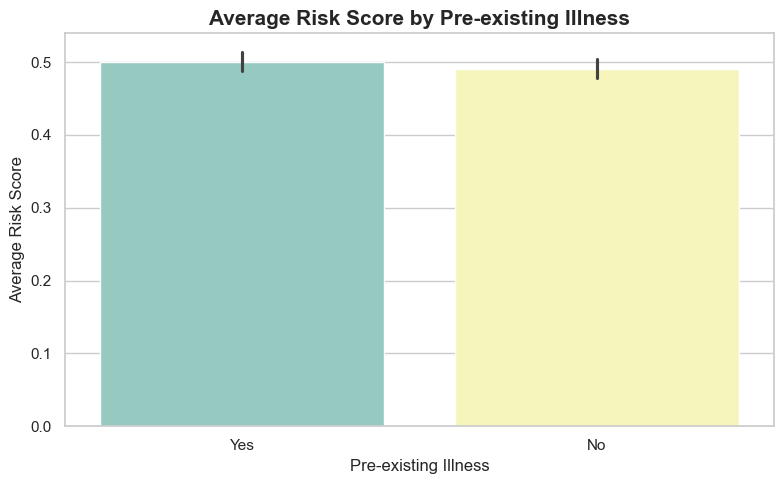

In [24]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=customer,
    x="pre_existing_illness",
    y="risk_score",
    estimator="mean",
    hue="pre_existing_illness",
    palette="Set3",
    legend=False
)

plt.title(
    "Average Risk Score by Pre-existing Illness",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Pre-existing Illness")
plt.ylabel("Average Risk Score")

plt.tight_layout()
plt.show()

### Region :

In [25]:
customer.groupby("region")["risk_score"].agg( ["count", "mean"]).sort_values("mean", ascending=False)

,count,mean
region,,
North,279,0.505018
South,270,0.501000
East,273,0.500330
North-East,254,0.493898
Central,287,0.492091
West,285,0.482667


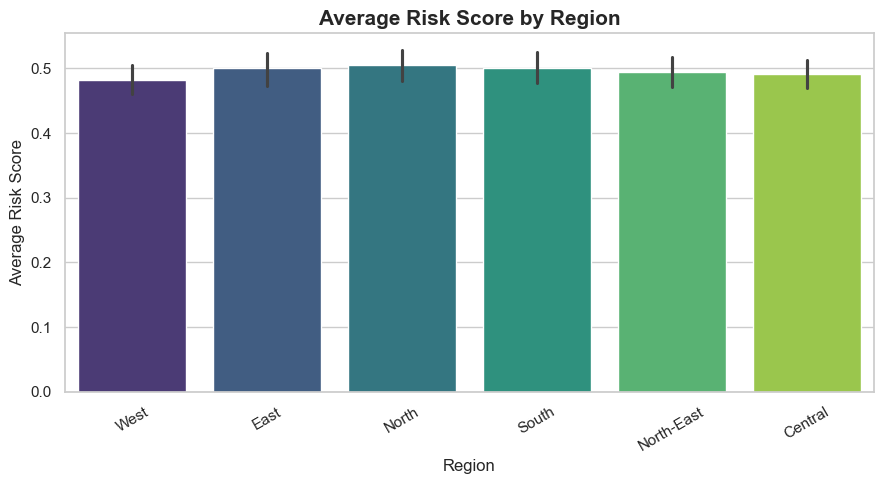

In [26]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=customer,
    x="region",
    y="risk_score",
    estimator="mean",
    hue="region",
    palette="viridis",
    legend=False
)

plt.title(
    "Average Risk Score by Region",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Region")
plt.ylabel("Average Risk Score")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

## Risk Score by Smoking Status :-

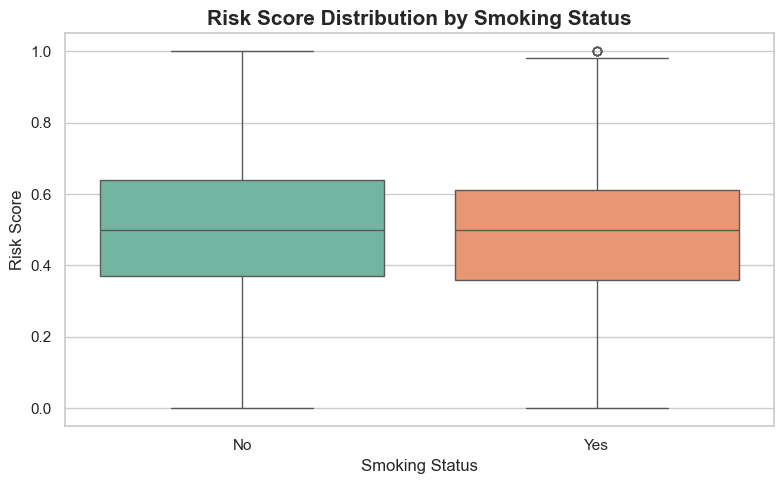

In [27]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=customer,
    x="smoking_status",
    y="risk_score",
    hue="smoking_status",
    palette=["#66C2A5", "#FC8D62"],
    legend=False
)

plt.title(
    "Risk Score Distribution by Smoking Status",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Smoking Status")
plt.ylabel("Risk Score")

plt.tight_layout()
plt.show()

# STATISTICAL ANALYSIS:-

## Independent T-test :-

## T-Test: Difference in Mean Risk Score by Smoking Status

Objective:
To determine whether the mean risk score differs significantly between the two smoking-status groups.

H₀ (Null Hypothesis): There is no significant difference in mean risk score between the two groups.

H₁ (Alternative Hypothesis): There is a significant difference in mean risk score between the two groups.

In [28]:
customer["smoking_status"].value_counts()

smoking_status
No     855
Yes    793
Name: count, dtype: int64

In [37]:
groups = customer.groupby("smoking_status")["risk_score"]

group_names = list(groups.groups.keys())

group1 = groups.get_group(group_names[0]).dropna()
group2 = groups.get_group(group_names[1]).dropna()

t_stat, p_value = ttest_ind(
    group1,
    group2,
    equal_var=False
)

print("Group 1:", group_names[0])
print("Group 2:", group_names[1])
print("Mean", group_names[0], ":", group1.mean())
print("Mean", group_names[1], ":", group2.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Reject H0.")
    print("There is a statistically significant difference in mean risk score.")
else:
    print("Conclusion: Fail to reject H0.")
    print("There is no statistically significant difference in mean risk score.")

Group 1: No
Group 2: Yes
Mean No : 0.5056491228070176
Mean Yes : 0.4850819672131147
T-statistic: 2.131798379600775
P-value: 0.03317209188704847
Conclusion: Reject H0.
There is a statistically significant difference in mean risk score.


## One-Way ANOVA :-

### ANOVA: Difference in Mean Risk Score Across Regions

Objective:
To determine whether the mean risk score differs significantly across the different regions.

H₀ (Null Hypothesis):
There is no significant difference in mean risk score across the regions.

H₁ (Alternative Hypothesis):
There is a significant difference in mean risk score across the regions.

In [38]:
anova_groups = [
    group["risk_score"].dropna()
    for _, group in customer.groupby("region")]

f_stat, p_value = f_oneway(*anova_groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Reject H0.")
    print("There is a statistically significant difference in mean risk score across regions.")
else:
    print("Conclusion: Fail to reject H0.")
    print("There is no statistically significant difference in mean risk score across regions.")

F-statistic: 0.4717272223493978
P-value: 0.7975495722578163
Conclusion: Fail to reject H0.
There is no statistically significant difference in mean risk score across regions.


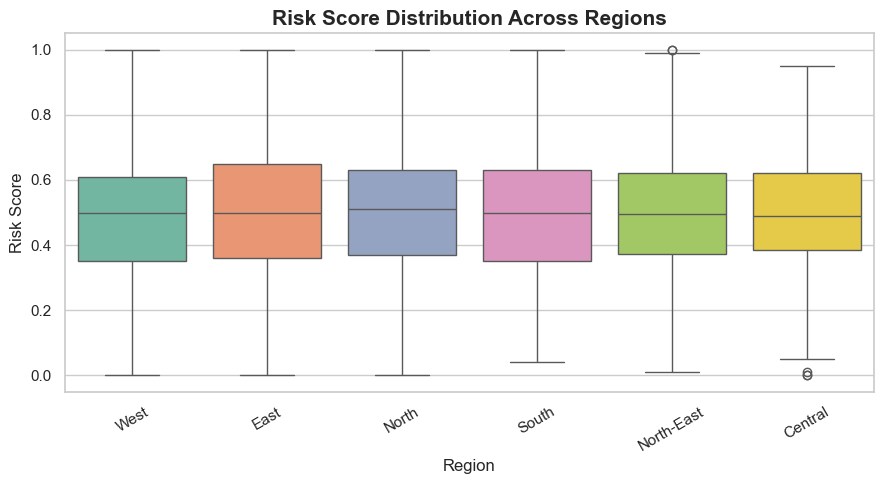

In [31]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=customer,
    x="region",
    y="risk_score",
    hue="region",
    palette="Set2",
    legend=False)

plt.title(
    "Risk Score Distribution Across Regions",
    fontsize=15,
    fontweight="bold")

plt.xlabel("Region")
plt.ylabel("Risk Score")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

## Chi-Square Test of Independence :-

### Chi-Square Test: Association Between Smoking Status and Claim Occurrence

Objective:
To determine whether smoking status and claim occurrence are statistically associated.

H₀ (Null Hypothesis):
There is no significant association between smoking status and claim occurrence.

H₁ (Alternative Hypothesis):
There is a significant association between smoking status and claim occurrence.

In [40]:
claim_customer = policy[
    ["policy_id", "customer_id"]
].merge(
    claims[["policy_id", "claim_id"]],
    on="policy_id",
    how="left")

claim_customer["has_claim"] = claim_customer["claim_id"].notna()

claim_flag = (
    claim_customer.groupby("customer_id")["has_claim"]
    .any()
    .reset_index())

chi_data = customer[
    ["customer_id", "smoking_status"]
].merge(
    claim_flag,
    on="customer_id",
    how="left")

chi_data["has_claim"] = chi_data["has_claim"].fillna(False)

contingency = pd.crosstab(
    chi_data["smoking_status"],
    chi_data["has_claim"])

print("Contingency Table:")
display(contingency)

Contingency Table:


has_claim,False,True
smoking_status,,
No,418,437
Yes,346,447


In [41]:
chi2, p_value, dof, expected = chi2_contingency(contingency)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Reject H0.")
    print("There is a statistically significant association between smoking status and claim occurrence.")
else:
    print("Conclusion: Fail to reject H0.")
    print("There is no statistically significant association between smoking status and claim occurrence.")

Chi-square statistic: 4.363448105712627
Degrees of freedom: 1
P-value: 0.0367179134334582
Conclusion: Reject H0.
There is a statistically significant association between smoking status and claim occurrence.


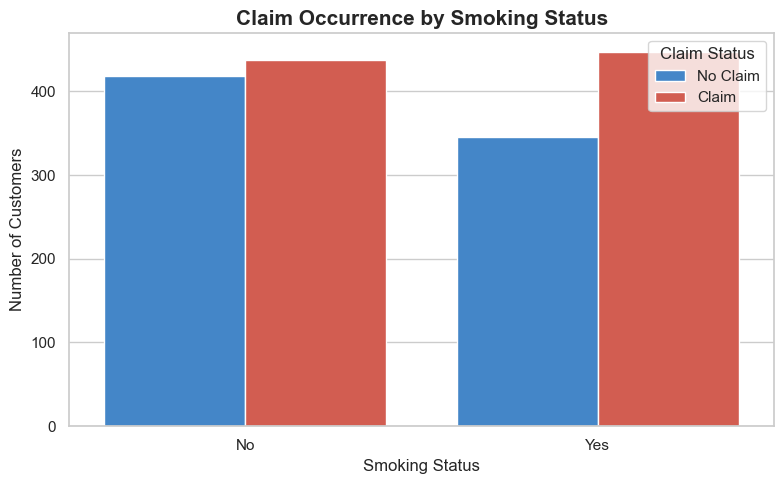

In [36]:
claim_plot = (
    chi_data.groupby(["smoking_status", "has_claim"])
    .size()
    .reset_index(name="count")
)

claim_plot["Claim Status"] = claim_plot["has_claim"].map({
    True: "Claim",
    False: "No Claim"
})

plt.figure(figsize=(8,5))

sns.barplot(
    data=claim_plot,
    x="smoking_status",
    y="count",
    hue="Claim Status",
    palette=["#2E86DE", "#E74C3C"]
)

plt.title(
    "Claim Occurrence by Smoking Status",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Smoking Status")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [43]:
groups = customer.groupby("smoking_status")["risk_score"]

group_names = list(groups.groups.keys())

group1 = groups.get_group(group_names[0]).dropna()
group2 = groups.get_group(group_names[1]).dropna()

t_stat, t_p_value = ttest_ind(
    group1,
    group2,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", t_p_value)

T-statistic: 2.131798379600775
P-value: 0.03317209188704847


In [44]:
anova_groups = [
    group["risk_score"].dropna()
    for _, group in customer.groupby("region")
]

f_stat, anova_p_value = f_oneway(*anova_groups)

print("F-statistic:", f_stat)
print("P-value:", anova_p_value)

F-statistic: 0.4717272223493978
P-value: 0.7975495722578163


In [45]:
chi2, chi_p_value, dof, expected = chi2_contingency(contingency)

print("Chi-square statistic:", chi2)
print("P-value:", chi_p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 4.363448105712627
P-value: 0.0367179134334582
Degrees of freedom: 1


In [46]:
summary = pd.DataFrame({
    "Test": [
        "Independent T-Test",
        "One-Way ANOVA",
        "Chi-Square Test"
    ],
    "Statistic": [
        t_stat,
        f_stat,
        chi2
    ],
    "P_Value": [
        t_p_value,
        anova_p_value,
        chi_p_value
    ]
})

summary

,Test,Statistic,P_Value
0,Independent T-Test,2.131798,0.033172
1,One-Way ANOVA,0.471727,0.797550
2,Chi-Square Test,4.363448,0.036718


In [47]:
summary["Decision"] = np.where(
    summary["P_Value"] < 0.05,
    "Reject H0",
    "Fail to Reject H0"
)

summary

,Test,Statistic,P_Value,Decision
0,Independent T-Test,2.131798,0.033172,Reject H0
1,One-Way ANOVA,0.471727,0.797550,Fail to Reject H0
2,Chi-Square Test,4.363448,0.036718,Reject H0


# Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to understand customer risk patterns, policy characteristics, claim behavior, fraud indicators, and customer satisfaction.

## 1. Customer Risk Analysis

In [48]:
customer["risk_category"] = pd.cut(
    customer["risk_score"],
    bins=[-np.inf, 0.30, 0.70, np.inf],
    labels=["Low Risk", "Medium Risk", "High Risk"])

customer["risk_category"].value_counts()

risk_category
Medium Risk    1149
Low Risk        265
High Risk       234
Name: count, dtype: int64

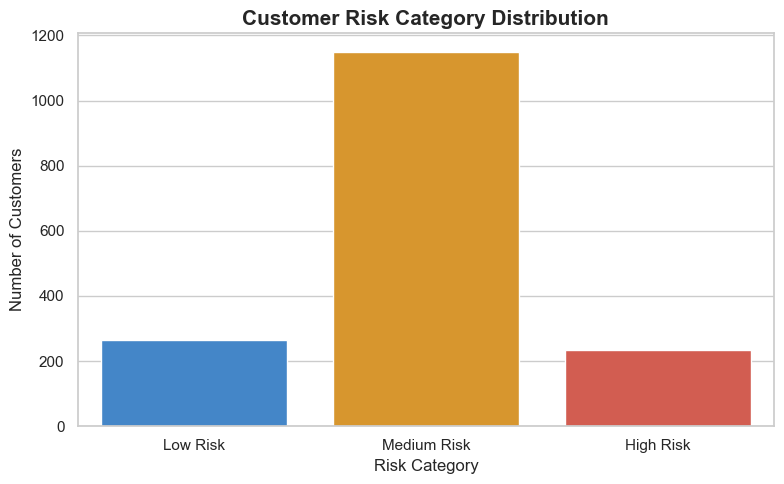

In [49]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=customer,
    x="risk_category",
    hue="risk_category",
    palette=["#2E86DE", "#F39C12", "#E74C3C"],
    legend=False)

plt.title(
    "Customer Risk Category Distribution",
    fontsize=15,
    fontweight="bold")
plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

## 2. Risk Drivers

### 2.1 Smoking Status

In [50]:
customer.groupby("smoking_status")["risk_score"].agg(
    ["count", "mean"]).sort_values("mean", ascending=False)

,count,mean
smoking_status,,
No,855,0.505649
Yes,793,0.485082


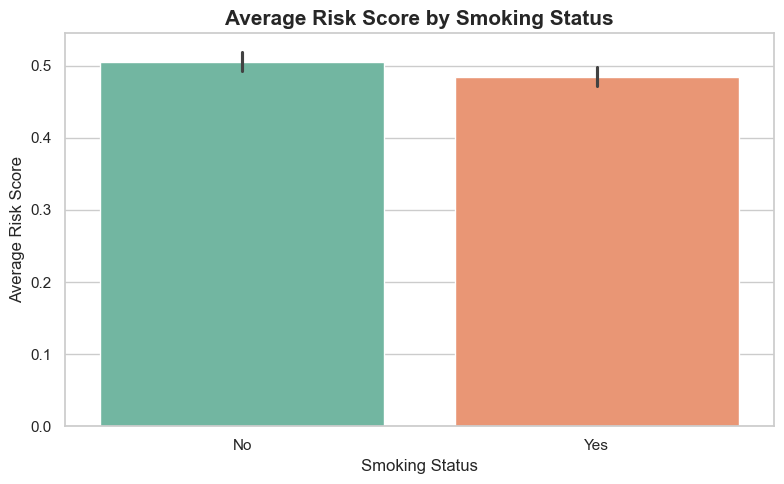

In [51]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=customer,
    x="smoking_status",
    y="risk_score",
    estimator="mean",
    hue="smoking_status",
    palette="Set2",
    legend=False)

plt.title(
    "Average Risk Score by Smoking Status",
    fontsize=15,
    fontweight="bold")
plt.xlabel("Smoking Status")
plt.ylabel("Average Risk Score")
plt.tight_layout()
plt.show()

### 2.2 Pre-existing Illness

In [52]:
customer.groupby("pre_existing_illness")["risk_score"].agg(
    ["count", "mean"]).sort_values("mean", ascending=False)

,count,mean
pre_existing_illness,,
Yes,823,0.500255
No,825,0.491261


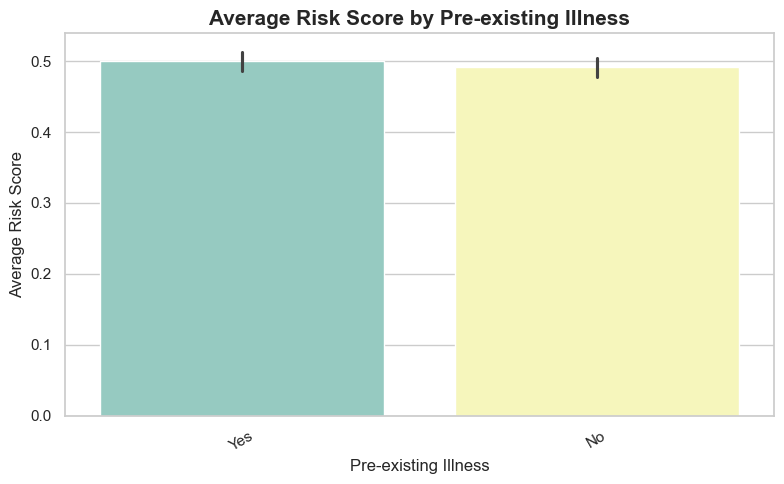

In [53]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=customer,
    x="pre_existing_illness",
    y="risk_score",
    estimator="mean",
    hue="pre_existing_illness",
    palette="Set3",
    legend=False)

plt.title(
    "Average Risk Score by Pre-existing Illness",
    fontsize=15,
    fontweight="bold")
plt.xlabel("Pre-existing Illness")
plt.ylabel("Average Risk Score")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### 2.3 Regional Risk Analysis

In [54]:
customer.groupby("region")["risk_score"].agg(
    ["count", "mean"]).sort_values("mean", ascending=False)

,count,mean
region,,
North,279,0.505018
South,270,0.501000
East,273,0.500330
North-East,254,0.493898
Central,287,0.492091
West,285,0.482667


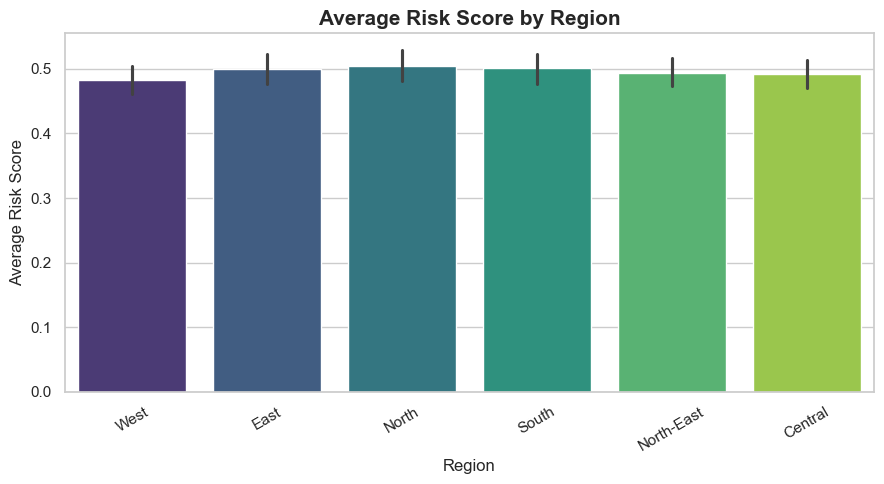

In [55]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=customer,
    x="region",
    y="risk_score",
    estimator="mean",
    hue="region",
    palette="viridis",
    legend=False)

plt.title(
    "Average Risk Score by Region",
    fontsize=15,
    fontweight="bold")
plt.xlabel("Region")
plt.ylabel("Average Risk Score")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 3. Claims Analysis

In [56]:
claims["claim_status"].value_counts()

claim_status
Approved    504
Pending     454
Rejected    448
Name: count, dtype: int64

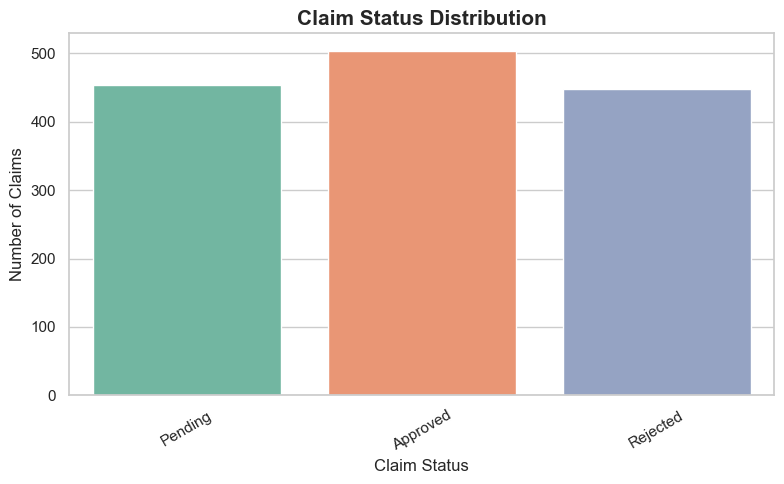

In [57]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=claims,
    x="claim_status",
    hue="claim_status",
    palette="Set2",
    legend=False)

plt.title(
    "Claim Status Distribution",
    fontsize=15,
    fontweight="bold")
plt.xlabel("Claim Status")
plt.ylabel("Number of Claims")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [59]:
claim_product = policy[
    ["policy_id", "product_type"]
].merge(
    claims[
        ["policy_id", "claim_amount"]
    ],
    on="policy_id",
    how="left")
product_claims = (
    claim_product.groupby("product_type")
    .agg(
        claim_count=("claim_amount", "count"),
        total_claim_amount=("claim_amount", "sum"),
        average_claim_amount=("claim_amount", "mean"))
    .sort_values("total_claim_amount", ascending=False))

product_claims

,claim_count,total_claim_amount,average_claim_amount
product_type,,,
Health,314,77777956.58,247700.498662
Property,285,75128333.72,263608.188491
Vehicle,282,68532832.91,243024.230177
Term,262,68210871.45,260346.837595
Whole,263,65973003.09,250847.920494


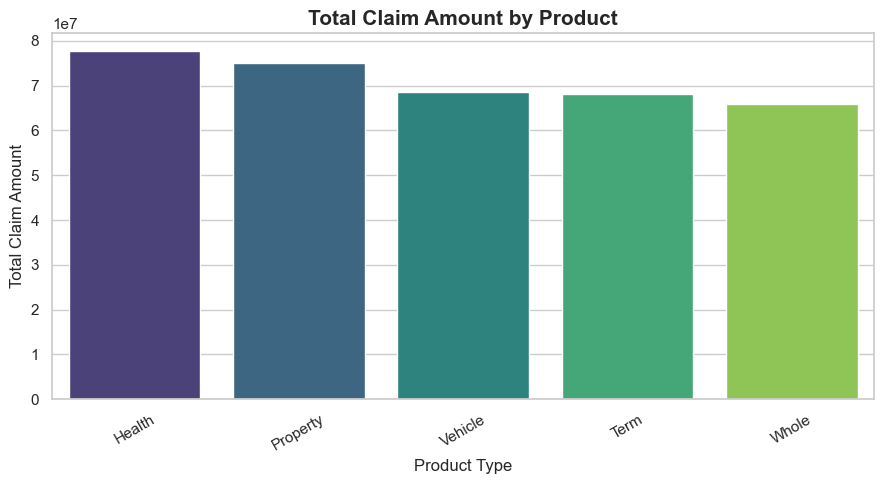

In [60]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=product_claims.reset_index(),
    x="product_type",
    y="total_claim_amount",
    hue="product_type",
    palette="viridis",
    legend=False)

plt.title(
    "Total Claim Amount by Product",
    fontsize=15,
    fontweight="bold")
plt.xlabel("Product Type")
plt.ylabel("Total Claim Amount")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 4. Fraud Analysis

In [61]:
claims["fraud_flag"].value_counts()

fraud_flag
No     717
Yes    689
Name: count, dtype: int64

In [62]:
fraud_summary = (
    claims.groupby("fraud_flag")
    .agg(
        claim_count=("claim_id", "count"),
        total_claim_amount=("claim_amount", "sum"),
        average_claim_amount=("claim_amount", "mean")))

fraud_summary

,claim_count,total_claim_amount,average_claim_amount
fraud_flag,,,
No,717,1.831718e+08,255469.776151
Yes,689,1.724512e+08,250291.971335


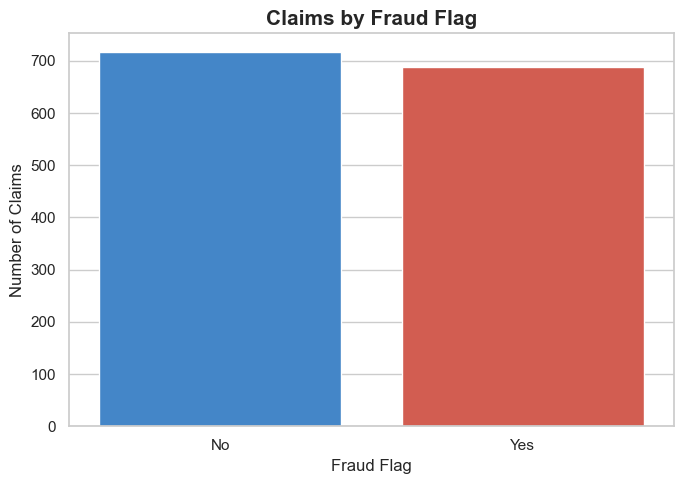

In [63]:
plt.figure(figsize=(7,5))

sns.barplot(
    data=fraud_summary.reset_index(),
    x="fraud_flag",
    y="claim_count",
    hue="fraud_flag",
    palette=["#2E86DE", "#E74C3C"],
    legend=False)

plt.title(
    "Claims by Fraud Flag",
    fontsize=15,
    fontweight="bold")
plt.xlabel("Fraud Flag")
plt.ylabel("Number of Claims")
plt.tight_layout()
plt.show()

## 5. Policy and Premium Analysis

In [64]:
product_summary = (
    policy.groupby("product_type")
    .agg(
        policies=("policy_id", "count"),
        total_coverage=("coverage_amount", "sum"),
        total_premium=("annual_premium", "sum"),
        average_premium=("annual_premium", "mean"))
    .sort_values("total_premium", ascending=False))

product_summary

,policies,total_coverage,total_premium,average_premium
product_type,,,,
Vehicle,591,3.207898e+08,16070206.13,27191.550135
Health,585,3.092402e+08,15456871.14,26422.001949
Term,545,2.989367e+08,14790116.22,27137.827927
Property,567,3.048110e+08,14729902.02,25978.663175
Whole,540,2.974836e+08,14419179.73,26702.184685


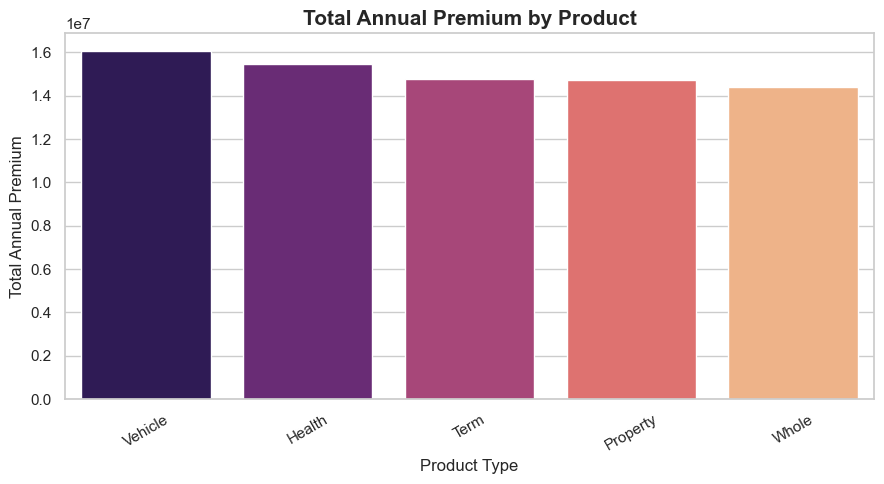

In [65]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=product_summary.reset_index(),
    x="product_type",
    y="total_premium",
    hue="product_type",
    palette="magma",
    legend=False)

plt.title(
    "Total Annual Premium by Product",
    fontsize=15,
    fontweight="bold")
plt.xlabel("Product Type")
plt.ylabel("Total Annual Premium")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 6. Customer Feedback Analysis

In [66]:
print("Total Feedback:", len(feedback))
print(
    "Average Satisfaction:",
    round(feedback["satisfaction_score"].mean(), 2))

Total Feedback: 1000
Average Satisfaction: 3.22


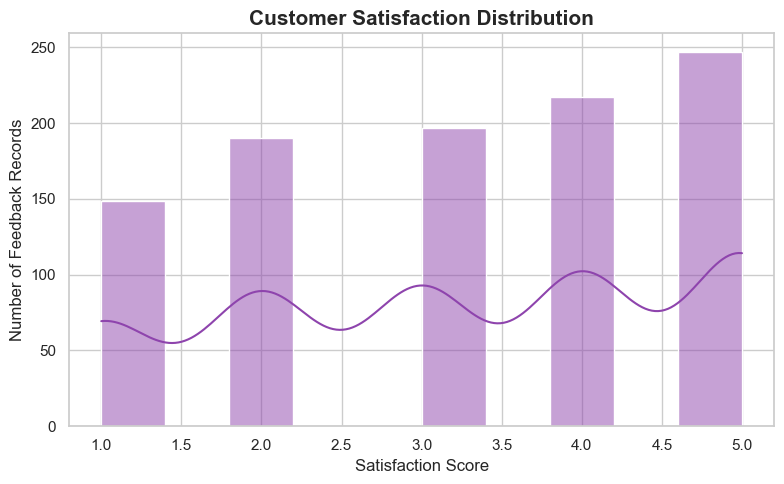

In [67]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=feedback,
    x="satisfaction_score",
    bins=10,
    kde=True,
    color="#8E44AD")

plt.title(
    "Customer Satisfaction Distribution",
    fontsize=15,
    fontweight="bold")
plt.xlabel("Satisfaction Score")
plt.ylabel("Number of Feedback Records")
plt.tight_layout()
plt.show()

## 9. Key Findings :

- Medium-risk customers represent the largest risk category.
- Smoking status shows differences in average risk score between the two groups.
- Customers with pre-existing illness show a slightly different average risk score compared with those without illness.
- Claim activity is distributed across Approved, Pending, and Rejected outcomes.
- Fraud-flagged and non-fraud-flagged claims show differences in claim volume and claim amounts.
- Policy and premium characteristics vary across product types.
- Customer feedback shows an average satisfaction score of 3.22 out of 5.

## 10. Business Recommendations

1. Prioritize monitoring of high-risk customers for proactive risk management.

2. Use risk scoring to support customer segmentation and underwriting decisions.

3. Investigate factors associated with higher claim activity and claim amounts.

4. Strengthen fraud-review processes for claims flagged as potentially fraudulent.

5. Review product-level premium and claim patterns to improve pricing decisions.

6. Use customer feedback and satisfaction scores to identify service-improvement opportunities.

7. Use regional risk patterns to support targeted risk-management strategies.

## 11. Conclusion :

This analysis provides a data-driven view of customer risk, claims, fraud indicators, policy premiums, and customer satisfaction. Exploratory analysis and statistical testing were used to identify important patterns and relationships within the insurance data. The findings can support better risk assessment, claims management, fraud monitoring, pricing decisions, and customer-service improvement.